# Credit Portfolio Segmentation and Risk Pattern Analysis

## Step 1: Data Collection and Understanding

**Project Domain:
** Banking and Financial Services
**Dataset:** loans_granting_model_dataset
**Techniques:** Exploratory Data Analysis, Data Cleaning, Feature Engineering, Encoding and Feature Scaling
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook

## 1. Project Overview

### 1.1 Introduction

Financial institutions need to understand borrower characteristics to manage lending portfolios, identify different borrower profiles, and assess potential credit risks.

This project aims to segment borrowers into meaningful groups using unsupervised machine learning techniques. The analysis uses the Lending Club loan portfolio dataset to identify borrower segments based on financial characteristics, employment information, loan purpose, and home ownership.

Historical loan default information is retained separately and is **not** used as a clustering input. It is used after clustering to evaluate the risk characteristics of the identified borrower segments.

### 1.2 Project Objectives

- Understand the structure and characteristics of the Lending Club dataset.
- Perform exploratory data analysis and identify data-quality issues.
- Clean missing values and investigate outliers.
- Transform and encode relevant borrower features.
- Standardize numerical variables for distance-based clustering.
- Prepare a reliable dataset for unsupervised learning.

### 1.3 Dataset Description

| Description | Value |
|---|---|
| Total records | 1,347,681 |
| Original columns | 15 |
| Duplicate records | 0 |
| Duplicate loan IDs | 0 |

> The final number of clustering features will be reported in the feature engineering step, once encoding is complete.

### Original Dataset Features

| Feature | Description |
|---|---|
| id | Unique loan identifier |
| issue_d | Loan issue date |
| revenue | Borrower annual revenue (income) |
| dti_n | Debt-to-income ratio |
| loan_amnt | Loan amount |
| fico_n | FICO credit score |
| experience_c | Employment experience indicator |
| emp_length | Employment length |
| purpose | Loan purpose |
| home_ownership_n | Home ownership status |
| addr_state | Borrower's state |
| zip_code | Masked ZIP code |
| Default | Historical loan default indicator |
| title | Loan title |
| desc | Loan description |

### 1.4 Questions this step answers

1. Is the dataset suitable for unsupervised learning?
2. Are the required financial and credit features available?
3. Which columns should be removed, retained or transformed?
4. Do missing values, duplicates and outliers exist?
5. Can we implement K-Means, Hierarchical Clustering and DBSCAN?

## 2. Data Loading and Basic Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")

DATA_PATH = r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\loans_granting_model_dataset.csv"

# low_memory=False avoids the mixed-type DtypeWarning on the 'desc' column
df = pd.read_csv(DATA_PATH,low_memory=False)
## The dataset was loaded using the Pandas read_csv() function. 
## The parameter low_memory=False was specified to prevent mixed-type warnings during import and to ensure accurate data type inference across all columns.

print("DATASET LOADED SUCCESSFULLY")
print("=" * 50)
print("Shape:", df.shape)

DATASET LOADED SUCCESSFULLY
Shape: (1347681, 15)


In [2]:
print("First 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

First 5 Records:


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN



Last 5 Records:


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
1347676,89905081,Oct-2016,130000.0,20.59,18000,737.0,1,5 years,home_improvement,OWN,TX,775xx,0,Home improvement,NaN
1347677,88948836,Oct-2016,180792.0,22.03,29400,707.0,1,9 years,debt_consolidation,MORTGAGE,CA,900xx,0,Debt consolidation,NaN
1347678,89996426,Oct-2016,157000.0,10.34,32000,737.0,1,3 years,home_improvement,MORTGAGE,AZ,863xx,1,Home improvement,NaN
1347679,90006534,Oct-2016,150000.0,12.25,16000,667.0,1,10+ years,medical,RENT,NC,284xx,0,Medical expenses,NaN
1347680,88224441,Oct-2016,110000.0,18.30,24000,662.0,1,6 years,debt_consolidation,RENT,FL,334xx,1,Debt consolidation,NaN



Column Names:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title', 'desc']

Data Types:
id                    int64
issue_d                 str
revenue             float64
dti_n               float64
loan_amnt             int64
fico_n              float64
experience_c          int64
emp_length              str
purpose                 str
home_ownership_n        str
addr_state              str
zip_code                str
Default               int64
title                   str
desc                    str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  f

### 2.1 Column notes (to verify during EDA)

- **fico_n**: values such as 847.5 suggest this is derived (for example the average of a low/high FICO range), not a raw score. Checked below.
- **dti_n**: a value of 999 is almost certainly a special code rather than a real ratio. Checked below.
- **revenue**: annual income; extreme maximum (about $11M) needs investigation.
- **experience_c**: nearly constant; relationship to `emp_length == "NI"` is checked below.

## 3. Missing Value Analysis

In [3]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100,
    "Non_Missing_Count": df.notnull().sum()
}).sort_values(by="Missing_Percentage", ascending=False)

display(missing_report.round(3))

,Missing_Count,Missing_Percentage,Non_Missing_Count
desc,1228582,91.163,119099
title,16657,1.236,1331024
zip_code,1,0.000,1347680
dti_n,0,0.000,1347681
id,0,0.000,1347681
issue_d,0,0.000,1347681
revenue,0,0.000,1347681
experience_c,0,0.000,1347681
fico_n,0,0.000,1347681
loan_amnt,0,0.000,1347681


In [4]:
# The single record with a missing zip_code
display(df[df["zip_code"].isnull()])

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
999330,96387212,Jan-2017,40000.0,22.86,5600,672.0,1,10+ years,debt_consolidation,MORTGAGE,AL,NaN,0,Debt consolidation,NaN


### Missing-value analysis: interpretation

All financial features are 100% complete.

| Column | Missing % | Decision |
|---|---|---|
| desc | 91.163% | Drop |
| title | 1.236% | Exclude from initial clustering |
| zip_code | 0.0001% (1 value) | Excluded from clustering; handle separately if used later |
| dti_n | 0% | Retain |
| revenue | 0% | Retain |
| loan_amnt | 0% | Retain |
| fico_n | 0% | Retain |
| experience_c | 0% | Exclude (near constant, see below) |
| emp_length | 0% | Retain |
| purpose | 0% | Retain |
| home_ownership_n | 0% | Retain |
| addr_state | 0% | Retain |

**Key observations**

1. **desc**: 1,228,582 missing, only 119,099 records have a description. Remove from clustering.
2. **title**: 16,657 missing (about 1.24%) and it overlaps substantially with `purpose`. Exclude from initial clustering.
3. **zip_code**: one missing value; ZIP codes are partially masked (for example `945xx`), so investigate the format before any geographic analysis.

## 4. Categorical Feature Analysis

In [5]:
categorical_features = ["emp_length", "purpose", "home_ownership_n", "addr_state", "zip_code"]

for col in categorical_features:
    print("\n" + "=" * 50)
    print("FEATURE:", col)
    print("Unique Values:", df[col].nunique())
    print("\nTop 15 Categories:")
    print(df[col].value_counts(dropna=False).head(15))

print("\nexperience_c distribution:")
print(df["experience_c"].value_counts())


FEATURE: emp_length
Unique Values: 12

Top 15 Categories:
emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

FEATURE: purpose
Unique Values: 14

Top 15 Categories:
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64

FEATURE: home_ownership_n
Unique Values: 4

Top 15 Categories:
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count

In [6]:
# Relationship between emp_length == "NI" and experience_c
print(pd.crosstab(df["emp_length"] == "NI", df["experience_c"],
                  rownames=["emp_length == NI"], colnames=["experience_c"]))

print("\nRecords with experience_c == 0:")
display(df.loc[df["experience_c"] == 0, "emp_length"].value_counts())

experience_c       0        1
emp_length == NI             
False             25  1269468
True               0    78188

Records with experience_c == 0:


emp_length
< 1 year     14
1 year        3
10+ years     3
3 years       2
9 years       1
6 years       1
2 years       1
Name: count, dtype: int64

### Categorical feature analysis: interpretation

**emp_length** (12 categories): retain.
10+ years is the largest group (442,667). Convert to an ordinal numeric feature and treat `NI` (78,188) as a separate unknown category. Do not treat unknown as zero years.

**purpose** (14 categories): retain.
Debt consolidation (781,206) and credit card (295,551) dominate. One-hot encode all 14 categories initially.

**home_ownership_n** (4 categories): retain.
MORTGAGE 666,594; RENT 535,585; OWN 144,985; OTHER 517. Keep all four categories initially, including the small OTHER group.

**addr_state** (51 values): retain for geographic analysis.
Largest populations: CA (196,805), TX (110,307), NY (110,075), FL (95,815), IL (51,858). Compare clustering with and without state before deciding whether geography improves the segments, and avoid giving geography an outsized influence over financial clusters.

**zip_code** (945 prefixes): exclude from initial clustering. Use `addr_state` for the first geographic analysis.

**experience_c**: 1,347,656 ones and 25 zeros. Almost constant, so it provides no separation. Remove from clustering.

## 5. Numerical Feature Analysis and Outlier Investigation

In [7]:
numerical_features = ["revenue", "dti_n", "loan_amnt", "fico_n", "experience_c"]

display(
    df[numerical_features]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

outlier_results = []
for col in numerical_features:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": count,
        "Outlier_Percentage": count / len(df) * 100
    })

display(pd.DataFrame(outlier_results).round(2))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
revenue,1347681.0,77369.683174,70362.989597,1896.0,19000.0,28329.0,46600.00,65000.00,92000.00,160000.00,260000.00,10999200.0
dti_n,1347681.0,18.299091,11.152139,0.0,1.8,5.0,11.82,17.63,24.07,32.99,38.48,999.0
loan_amnt,1347681.0,14408.230490,8715.347372,500.0,1500.0,3200.0,7975.00,12000.00,20000.00,32800.00,35000.00,40000.0
fico_n,1347681.0,698.158922,31.848725,612.0,662.0,662.0,672.00,692.00,712.00,762.00,802.00,847.5
experience_c,1347681.0,0.999981,0.004307,0.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.0


,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,revenue,-21500.00,160100.00,62998,4.67
1,dti_n,-6.56,42.44,5506,0.41
2,loan_amnt,-10062.50,38037.50,7131,0.53
3,fico_n,612.00,772.00,46490,3.45
4,experience_c,1.00,1.00,25,0.00


In [8]:
# --- DTI: investigate special / invalid values ---
print("dti_n == 999        :", (df["dti_n"] == 999).sum())
print("dti_n >= 100        :", (df["dti_n"] >= 100).sum())
print("dti_n > 60          :", (df["dti_n"] > 60).sum())
print("dti_n == 0          :", (df["dti_n"] == 0).sum())
print("dti_n < 0           :", (df["dti_n"] < 0).sum())

print("\nTop 10 highest dti_n values:")
print(df["dti_n"].nlargest(10).tolist())

print("\nDefault rate for dti_n >= 100 vs rest:")
print(df.groupby(df["dti_n"] >= 100)["Default"].agg(["mean", "count"]))

dti_n == 999        : 38
dti_n >= 100        : 535
dti_n > 60          : 1718
dti_n == 0          : 835
dti_n < 0           : 0

Top 10 highest dti_n values:
[999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0]

Default rate for dti_n >= 100 vs rest:
          mean    count
dti_n                  
False  0.19976  1347146
True   0.26729      535


In [9]:
# --- Revenue: investigate extreme values ---
print("Top 20 revenue values:")
print(df["revenue"].nlargest(20).tolist())

for threshold in [500_000, 1_000_000, 5_000_000]:
    print(f"revenue > {threshold:>9,}: {(df['revenue'] > threshold).sum()}")

print("\nrevenue <= 0:", (df["revenue"] <= 0).sum())

Top 20 revenue values:
[10999200.0, 9550000.0, 9522972.0, 9500000.0, 9300000.0, 9225000.0, 9000000.0, 8900060.0, 8706582.0, 8700000.0, 8500021.0, 8400000.0, 8300000.0, 8253000.0, 8121180.0, 7600000.0, 7500000.0, 7446395.0, 7200000.0, 7141778.0]
revenue >   500,000: 1789
revenue > 1,000,000: 294
revenue > 5,000,000: 41

revenue <= 0: 0


In [10]:
# --- FICO: investigate non-integer values (likely averaged low/high scores) ---
print("Records with fractional fico_n:", (df["fico_n"] % 1 != 0).sum())
print("\nfico_n value counts (top 10):")
print(df["fico_n"].value_counts().head(10))
print("\nHighest fico_n values:")
print(df["fico_n"].value_counts().sort_index(ascending=False).head(10))

Records with fractional fico_n: 185

fico_n value counts (top 10):
fico_n
662.0    121011
672.0    117358
667.0    117006
677.0    104741
682.0    103497
687.0     90834
692.0     88357
697.0     79222
702.0     72873
707.0     65498
Name: count, dtype: int64

Highest fico_n values:
fico_n
847.5     185
842.0     254
837.0     401
832.0     700
827.0    1069
822.0    1393
817.0    1877
812.0    2377
807.0    3320
802.0    3869
Name: count, dtype: int64


C:\Users\VIDYAPRIYA V\AppData\Local\Temp\ipykernel_19388\3623391455.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, i].boxplot(df[col], vert=False, showfliers=True)
C:\Users\VIDYAPRIYA V\AppData\Local\Temp\ipykernel_19388\3623391455.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, i].boxplot(df[col], vert=False, showfliers=True)
C:\Users\VIDYAPRIYA V\AppData\Local\Temp\ipykernel_19388\3623391455.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, i].boxplot(df[col], vert=False, showfliers=True)
C:\Users\VIDYAPRIYA V\AppData\Local\Temp\ipykernel_19388\3623391455.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated 

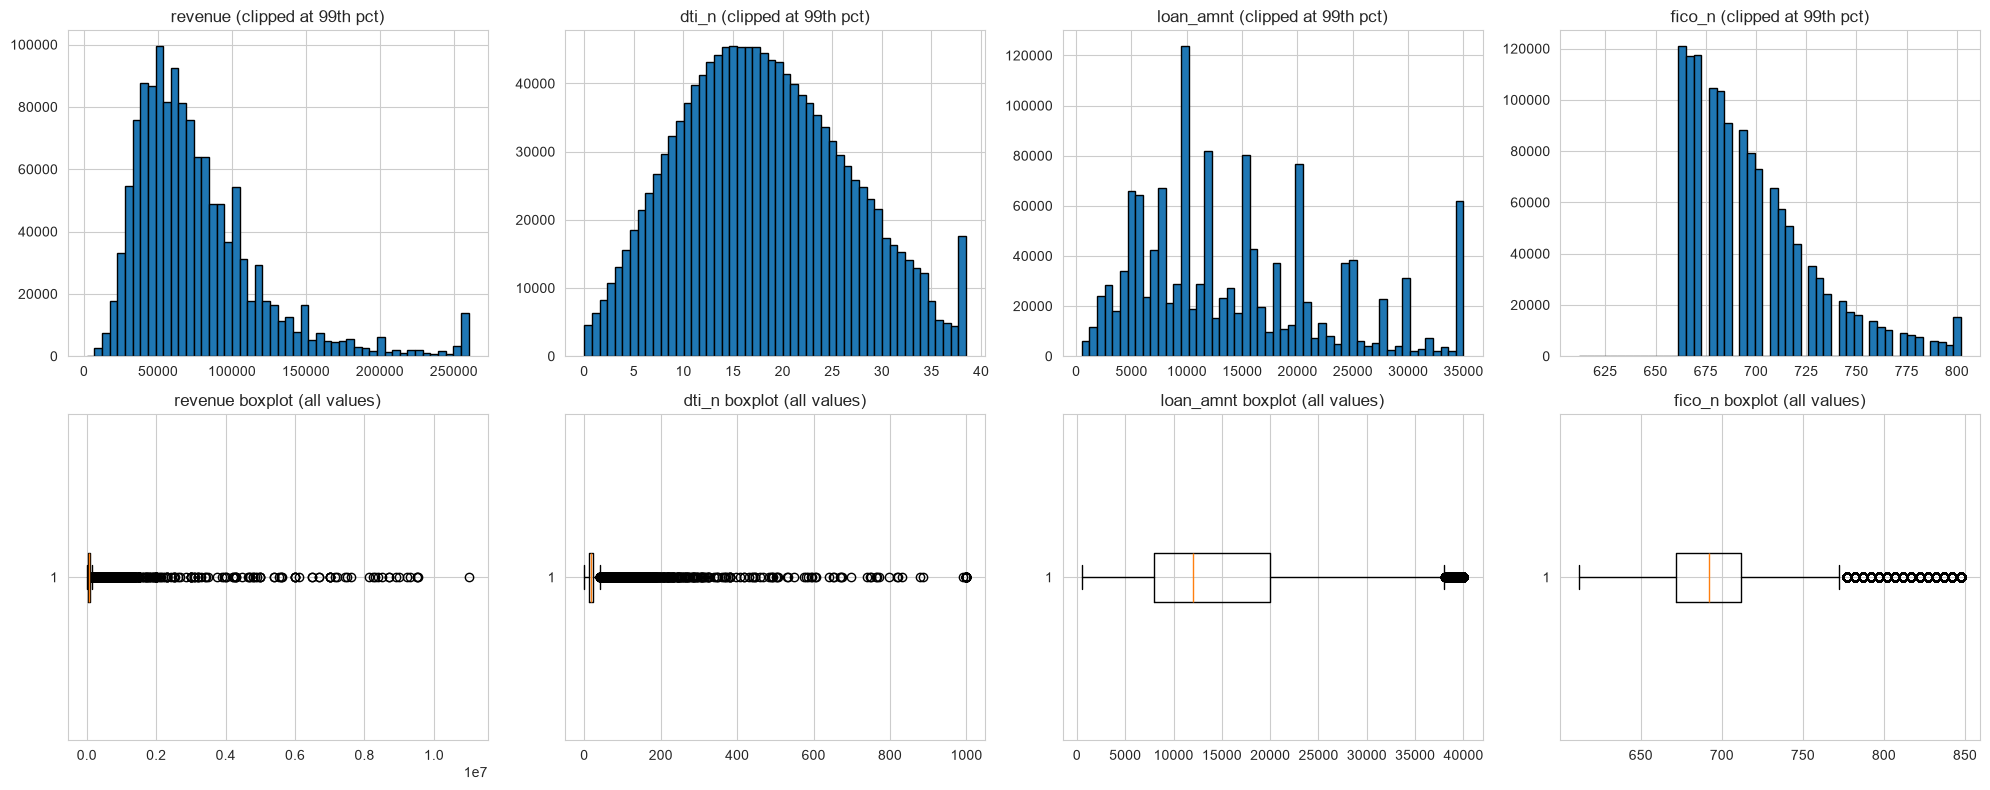

In [11]:
# --- Distributions: histograms (clipped at the 99th percentile for readability) and boxplots ---
plot_cols = ["revenue", "dti_n", "loan_amnt", "fico_n"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, col in enumerate(plot_cols):
    clipped = df[col].clip(upper=df[col].quantile(0.99))
    axes[0, i].hist(clipped, bins=50, edgecolor="black")
    axes[0, i].set_title(f"{col} (clipped at 99th pct)")
    axes[1, i].boxplot(df[col], vert=False, showfliers=True)
    axes[1, i].set_title(f"{col} boxplot (all values)")
plt.tight_layout()
plt.show()

### Numerical analysis: interpretation

**revenue (annual income)**: highly right-skewed

| Statistic | Value |
|---|---|
| Mean | $77,369.68 |
| Median (50%) | $65,000 |
| 25th percentile | $46,600 |
| 75th percentile | $92,000 |
| 95th percentile | $160,000 |
| Maximum | $10,999,200 |
| IQR outliers | 62,998 (4.67%) |

The mean is above the median and the maximum is far above the 99th percentile ($260,000). Some are genuine high earners, others need review. Consider a `log1p` transformation.

**dti_n (debt-to-income)**: invalid / extreme values present

| Statistic | Value |
|---|---|
| Mean | 18.30 |
| Median | 17.63 |
| 95th percentile | 32.99 |
| 99th percentile | 38.48 |
| Maximum | 999 |
| IQR outliers | 5,506 (0.41%) |

A DTI of 999 is likely a special code. Use the counts above to decide on treatment; do not blindly replace every high value with the median.

**loan_amnt**: well behaved. Mean $14,408, median $12,000, maximum $40,000, IQR outliers 7,131 (0.53%). High loans are legitimate profiles. Retain and scale; no outlier deletion.

**fico_n**: range 612 to 847.5. The 0.5 values suggest an averaged score; see the fractional check above. Do not remove high-score borrowers just because the IQR rule flags them (46,490, 3.45%).

**experience_c**: exclude from clustering (only 25 zeros).

## 6. Default Analysis (retained for post-clustering evaluation only)

Default Values:
Default
0    1078432
1     269249
Name: count, dtype: int64

Default Percentages:
Default
0    80.021311
1    19.978689
Name: proportion, dtype: float64

Overall Default Rate: 19.98 %


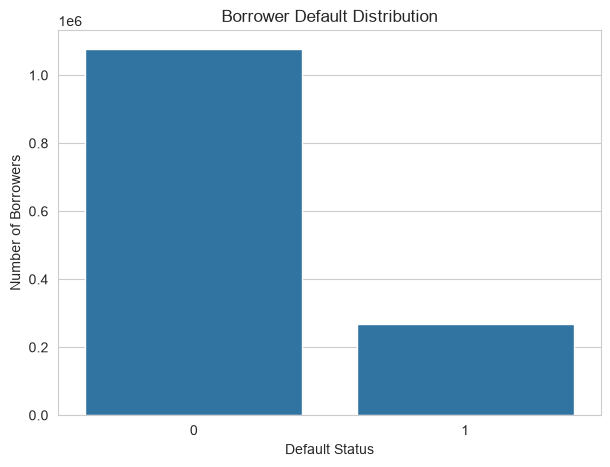

In [12]:
print("Default Values:")
print(df["Default"].value_counts(dropna=False))

print("\nDefault Percentages:")
print(df["Default"].value_counts(normalize=True) * 100)

print("\nOverall Default Rate:", round(df["Default"].mean() * 100, 2), "%")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Default")
plt.title("Borrower Default Distribution")
plt.xlabel("Default Status")
plt.ylabel("Number of Borrowers")
plt.show()

In [14]:
# Default rate by key categorical features
for col in ["purpose", "home_ownership_n", "emp_length"]:
    summary = (
        df.groupby(col)["Default"]
        .agg(Default_Rate="mean", Borrowers="count")
        .sort_values("Default_Rate", ascending=False)
    )
    summary["Default_Rate"] = (summary["Default_Rate"] * 100).round(2)
    print(f"\nDefault rate (%) by {col}")
    display(summary)


Default rate (%) by purpose


,Default_Rate,Borrowers
purpose,,
small_business,29.86,15575
renewable_energy,23.72,936
moving,23.41,9520
house,21.91,7294
medical,21.84,15606
debt_consolidation,21.15,781206
other,21.08,78263
educational,20.80,423
vacation,19.19,9083



Default rate (%) by home_ownership_n


,Default_Rate,Borrowers
home_ownership_n,,
RENT,23.23,535585
OWN,20.63,144985
OTHER,19.73,517
MORTGAGE,17.23,666594



Default rate (%) by emp_length


,Default_Rate,Borrowers
emp_length,,
NI,26.96,78188
1 year,20.59,88841
< 1 year,20.54,108517
3 years,19.99,107862
8 years,19.95,60808
9 years,19.91,51019
2 years,19.82,122091
4 years,19.76,80761
5 years,19.62,84326


**Note:** the overall default rate is 19.98% (269,249 of 1,347,681 loans). `Default` will not be used as a clustering input; it is used afterwards to profile the risk of each segment.

## 7. Loan Issue Date Analysis

Unparsed issue_d values: 0

Date Range:
Start: 2007-06-01 00:00:00
End  : 2018-12-01 00:00:00

Unique Issue Dates: 139

Year Distribution:
issue_d
2007       599
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    134804
2014    223102
2015    375543
2016    293057
2017    169117
2018     56160
Name: count, dtype: int64


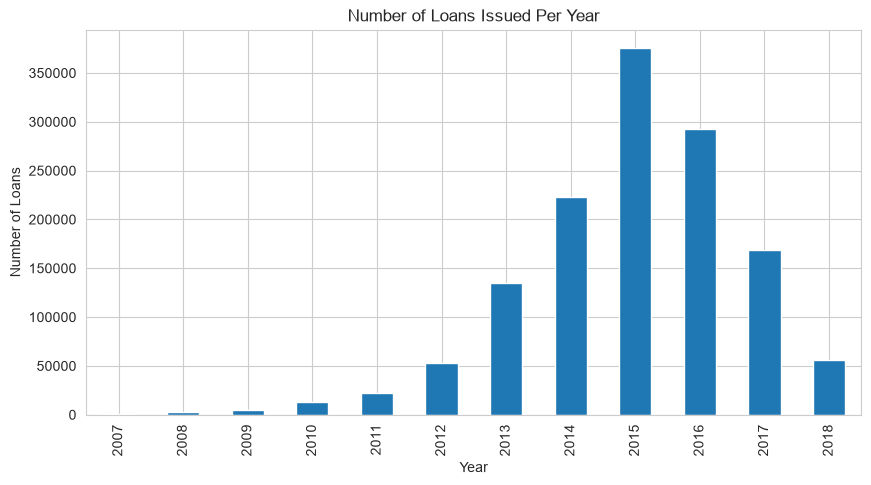

In [15]:
# Explicit format avoids slow, inconsistent dateutil parsing on 1.3M rows
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")

print("Unparsed issue_d values:", df["issue_d"].isnull().sum())
print("\nDate Range:")
print("Start:", df["issue_d"].min())
print("End  :", df["issue_d"].max())
print("\nUnique Issue Dates:", df["issue_d"].nunique())

print("\nYear Distribution:")
print(df["issue_d"].dt.year.value_counts().sort_index())

yearly_loans = df.groupby(df["issue_d"].dt.year).size()
yearly_loans.plot(kind="bar", figsize=(10, 5))
plt.title("Number of Loans Issued Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Loans")
plt.show()

## 8. Duplicate Analysis

In [16]:
print("Complete Duplicate Rows:", df.duplicated().sum())
print("Duplicate Loan IDs     :", df["id"].duplicated().sum())
print("Missing Loan IDs       :", df["id"].isnull().sum())

Complete Duplicate Rows: 0
Duplicate Loan IDs     : 0
Missing Loan IDs       : 0


### Duplicate analysis: results

| Validation | Result | Decision |
|---|---|---|
| Complete duplicate rows | 0 | No removal needed |
| Duplicate loan IDs | 0 | IDs are unique |
| Missing loan IDs | 0 | No missing IDs |

All 1,347,681 records are unique and retained. The `id` column is an identifier, not a borrower characteristic, so it is removed before clustering.

## 9. Correlation Analysis

Pearson Correlation Matrix:


,revenue,dti_n,loan_amnt,fico_n
revenue,1.000,-0.109,0.322,0.076
dti_n,-0.109,1.000,0.034,-0.060
loan_amnt,0.322,0.034,1.000,0.101
fico_n,0.076,-0.060,0.101,1.000


Spearman Correlation Matrix:


,revenue,dti_n,loan_amnt,fico_n
revenue,1.000,-0.186,0.493,0.110
dti_n,-0.186,1.000,0.046,-0.040
loan_amnt,0.493,0.046,1.000,0.117
fico_n,0.110,-0.040,0.117,1.000


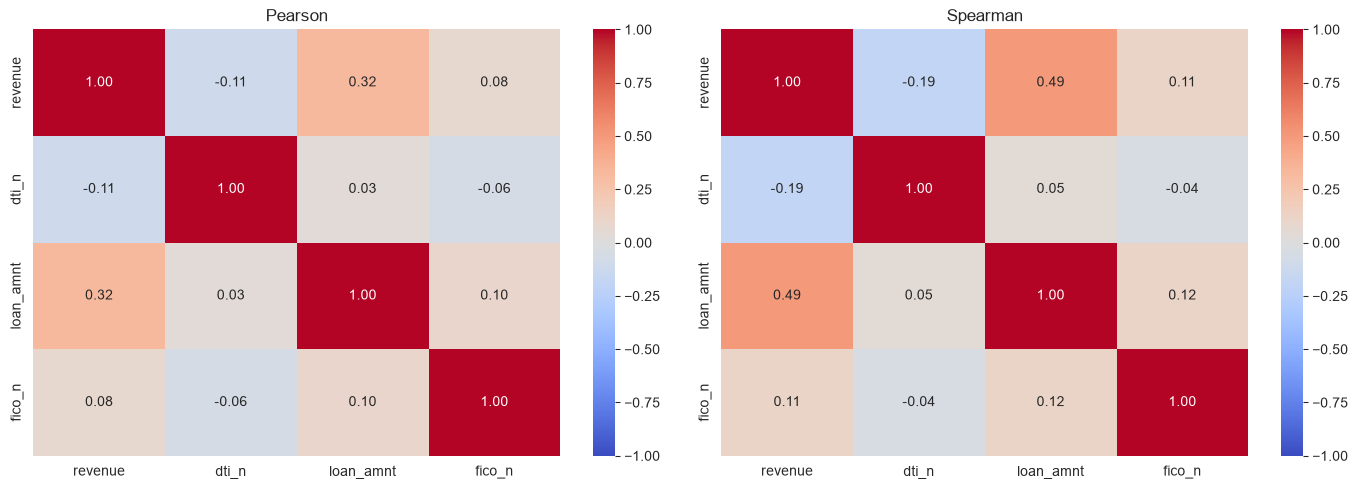

In [17]:
numeric_cols = ["revenue", "dti_n", "loan_amnt", "fico_n"]

pearson_corr = df[numeric_cols].corr(method="pearson")
# Spearman is rank-based and robust to the extreme revenue / DTI values
spearman_corr = df[numeric_cols].corr(method="spearman")

print("Pearson Correlation Matrix:")
display(pearson_corr.round(3))

print("Spearman Correlation Matrix:")
display(spearman_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

### Correlation analysis: interpretation

| Feature pair | Pearson | Interpretation |
|---|---|---|
| Revenue - Loan Amount | +0.322 | Moderate positive |
| Revenue - DTI | -0.109 | Weak negative |
| Loan Amount - FICO | +0.101 | Very weak positive |
| Revenue - FICO | +0.076 | Very weak positive |
| DTI - FICO | -0.060 | Very weak negative |
| DTI - Loan Amount | +0.034 | Essentially none |

Revenue and loan amount have the strongest relationship: borrowers with higher revenue tend to receive larger loans. Every other pair is weak (|r| near 0.1 or below), so no pair shows a strong linear relationship and multicollinearity is not a concern for clustering.

These are associations, not causal effects, and Pearson values can be distorted by extreme values (revenue up to about $11M, DTI 999). Compare with the Spearman matrix above, and recompute after outlier treatment in the next step.

## 10. Step 1 Summary and Decisions

| Item | Decision |
|---|---|
| Suitability for clustering | Dataset is suitable: complete financial features, no duplicates, unique IDs |
| Drop | `id`, `desc`, `title`, `zip_code`, `experience_c` (and `issue_d` unless time analysis is needed) |
| Retain (numeric) | `revenue`, `dti_n`, `loan_amnt`, `fico_n` |
| Retain (categorical) | `emp_length` (ordinal, `NI` as unknown), `purpose`, `home_ownership_n`, `addr_state` (test with/without) |
| Held out | `Default` (post-clustering risk evaluation only) |
| Outliers | Investigate DTI = 999 and extreme revenue; do not delete legitimate high loan or FICO values |
| Transformations planned | `log1p` for revenue, treatment of invalid DTI, one-hot encoding, standardization |

**Next step:** Data cleaning and feature engineering.